# IPL Analysis & Match Winner Prediction (Python + Machine Learning)

**Goal:** analyse IPL team and player performance, check whether the toss really matters, and build an ML model that predicts the match winner.

**Dataset:** Kaggle - *IPL Complete Dataset* (`matches.csv` and `deliveries.csv`). Upload both files to Colab (left sidebar -> Files).

**Steps:** 1) Load  2) Clean  3) Team analysis  4) Toss impact  5) Player analysis  6) ML win prediction  7) Conclusions

In [ ]:
!pip install kagglehub -q
import kagglehub, glob, shutil

path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
for f in glob.glob(path + "/*.csv"):
    shutil.copy(f, "/content/")
    print("Copied:", f.split("/")[-1])

Using Colab cache for faster access to the 'ipl-complete-dataset-20082020' dataset.
Copied: matches.csv
Copied: deliveries.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

MATCHES_PATH = "/content/matches.csv"
DELIVERIES_PATH = "/content/deliveries.csv"

matches = pd.read_csv(MATCHES_PATH)
deliveries = pd.read_csv(DELIVERIES_PATH)
print("Matches:", matches.shape, "| Deliveries:", deliveries.shape)
display(matches.head())
display(deliveries.head())

Matches: (1095, 20) | Deliveries: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


## 1. Data inspection

In [ ]:
matches.info()
print()
print("Missing values in matches:")
print(matches.isnull().sum()[matches.isnull().sum() > 0])
print("Duplicate rows:", matches.duplicated().sum())
print("Duplicate matches id:", matches["id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

## 2. Data cleaning
Teams changed names over the years (e.g. Delhi Daredevils -> Delhi Capitals), so we merge them to count each franchise once.

In [ ]:
team_map = {
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiant": "Rising Pune Supergiants",
    "Gujarat Lions": "Gujarat Titans",   # remove this line if you prefer to keep them separate
}
team_cols = ["team1", "team2", "toss_winner", "winner"]
for c in team_cols:
    matches[c] = matches[c].replace(team_map)
for c in ["batting_team", "bowling_team"]:
    deliveries[c] = deliveries[c].replace(team_map)

matches.drop_duplicates(inplace=True)
matches["date"] = pd.to_datetime(matches["date"], errors="coerce")
matches["season"] = matches["season"].astype(str)
matches["city"] = matches["city"].fillna("Unknown")

# Matches with no winner (abandoned / no result) cannot be used for win analysis
no_result = matches["winner"].isnull().sum()
matches = matches.dropna(subset=["winner"]).sort_values("date").reset_index(drop=True)
print("Removed", no_result, "matches with no result. Remaining:", len(matches))

# Make delivery column names consistent across dataset versions
if "batsman" in deliveries.columns and "batter" not in deliveries.columns:
    deliveries = deliveries.rename(columns={"batsman": "batter"})
print("Cleaning done.")

Removed 5 matches with no result. Remaining: 1090
Cleaning done.


## 3. Team performance

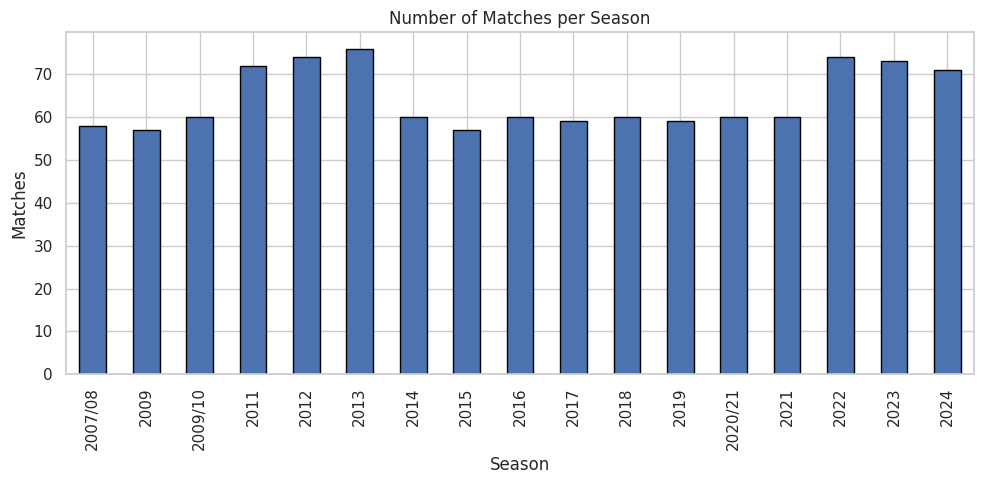

In [ ]:
# Matches per season
matches["season"].value_counts().sort_index().plot(kind="bar", edgecolor="black")
plt.title("Number of Matches per Season"); plt.xlabel("Season"); plt.ylabel("Matches")
plt.tight_layout(); plt.show()

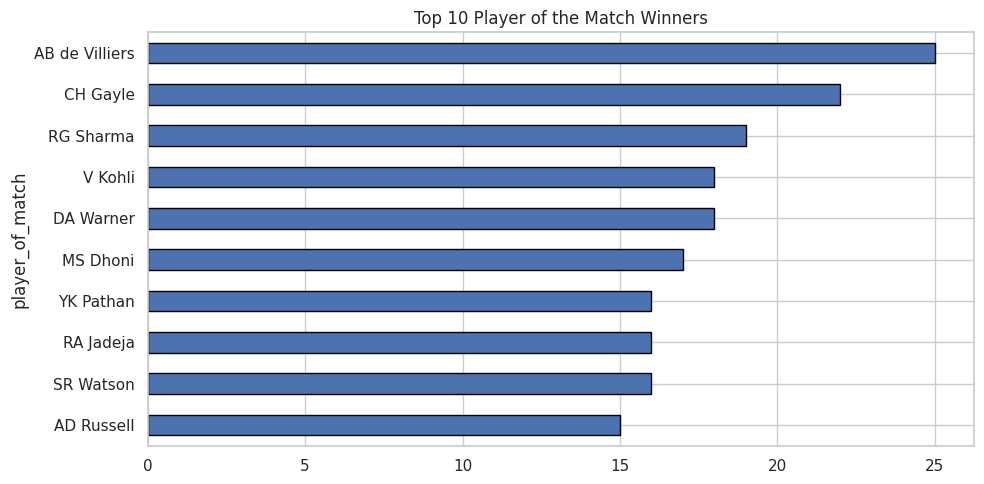

In [ ]:
# Most Player-of-the-Match awards
matches["player_of_match"].value_counts().head(10).plot(kind="barh", edgecolor="black")
plt.title("Top 10 Player of the Match Winners"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## 4. Does the toss matter?

Toss winner also won the match in 50.8% of matches


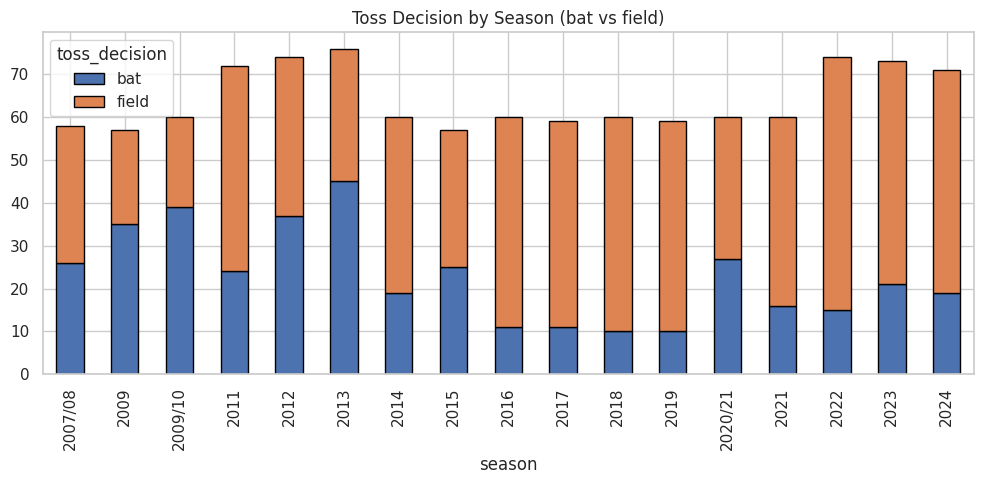

toss_decision
bat      45.4
field    53.9
Name: toss_win_match_win, dtype: float64


In [ ]:
matches["toss_win_match_win"] = matches["toss_winner"] == matches["winner"]
toss_pct = matches["toss_win_match_win"].mean() * 100
print(f"Toss winner also won the match in {toss_pct:.1f}% of matches")

# Toss decision trend by season
pd.crosstab(matches["season"], matches["toss_decision"]).plot(kind="bar", stacked=True, edgecolor="black")
plt.title("Toss Decision by Season (bat vs field)"); plt.tight_layout(); plt.show()

# Does choosing to bat or field help?
print(matches.groupby("toss_decision")["toss_win_match_win"].mean().mul(100).round(1))

## 5. Player performance

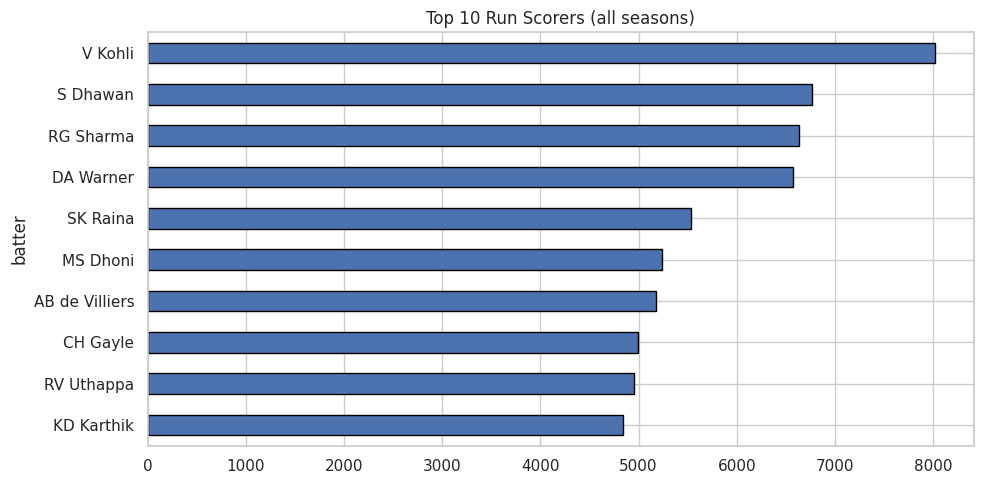

,runs,balls,strike_rate
batter,,,
AD Russell,2488,1423,174.8
H Klaasen,993,590,168.3
SP Narine,1534,925,165.8
LS Livingstone,939,578,162.5
N Pooran,1769,1092,162.0
RM Patidar,799,503,158.8
GJ Maxwell,2772,1769,156.7
V Sehwag,2728,1755,155.4
Abhishek Sharma,1377,887,155.2


In [ ]:
# Top run scorers
runs = deliveries.groupby("batter")["batsman_runs"].sum().sort_values(ascending=False)
runs.head(10).plot(kind="barh", edgecolor="black")
plt.title("Top 10 Run Scorers (all seasons)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

# Strike rate for batters with at least 500 balls faced (wides are not balls faced)
d = deliveries.copy()
if "extras_type" in d.columns:
    d = d[d["extras_type"] != "wides"]
elif "wide_runs" in d.columns:
    d = d[d["wide_runs"] == 0]
bat = d.groupby("batter").agg(runs=("batsman_runs", "sum"), balls=("batsman_runs", "count"))
bat = bat[bat["balls"] >= 500]
bat["strike_rate"] = (bat["runs"] / bat["balls"] * 100).round(1)
display(bat.sort_values("strike_rate", ascending=False).head(10))

## 6. Machine learning: predict the match winner
**Target:** did `team1` win (1) or not (0)?

**Features:** the two teams, toss winner, toss decision, venue, plus each team's win rate *before* the match (calculated in date order so we never use future information).

In [ ]:
# Rolling win rate before each match (no data leakage)
played_n, won_n = defaultdict(int), defaultdict(int)
t1_wr, t2_wr = [], []
for _, r in matches.iterrows():
    t1_wr.append(won_n[r.team1] / played_n[r.team1] if played_n[r.team1] else 0.5)
    t2_wr.append(won_n[r.team2] / played_n[r.team2] if played_n[r.team2] else 0.5)
    played_n[r.team1] += 1; played_n[r.team2] += 1; won_n[r.winner] += 1
matches["team1_wr"], matches["team2_wr"] = t1_wr, t2_wr
matches["wr_diff"] = matches["team1_wr"] - matches["team2_wr"]
matches["toss_winner_is_team1"] = (matches["toss_winner"] == matches["team1"]).astype(int)
matches["team1_won"] = (matches["winner"] == matches["team1"]).astype(int)

cat_feats = ["team1", "team2", "toss_decision", "venue"]
num_feats = ["toss_winner_is_team1", "team1_wr", "team2_wr", "wr_diff"]
X = matches[cat_feats + num_feats]
y = matches["team1_won"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (872, 8) Test: (218, 8)


In [ ]:
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
    ("num", "passthrough", num_feats),
])
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42),
}
results = {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
    acc = accuracy_score(y_test, pipe.predict(X_test))
    results[name] = (acc, pipe)
    print(f"{name}: accuracy = {acc:.3f}")

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline (always guess the majority class): {baseline:.3f}")

Logistic Regression: accuracy = 0.495
Random Forest: accuracy = 0.463
Baseline (always guess the majority class): 0.509


## 7. Conclusions
Fill these in with **your own numbers** from the charts above:
- Most successful team and its win %.
- Toss winner won the match in ___ % of games, so the toss matters (or only slightly matters).
- Top run scorer ___ and top wicket taker ___.
- Best model ___ reached ___ % accuracy vs a baseline of ___ %.
- **Limitations:** cricket is hard to predict (pitch, form, injuries, playing XI are not in the data).
- **Future work:** add player-level features, use a Streamlit web app, add an LLM that writes a match summary.